# Lab 04: How to remember a rep across conversations, and forget a customer

**CPU | API key: `OPENAI_API_KEY` | Self-study**

## Goal

A thread keeps one conversation, so in a new one the copilot has forgotten how the rep likes replies written. In this
lab you give the copilot a long-term memory: a store of a few facts per rep, written and read by tools, in every
thread. Then you meet its risk and its duty. The moment that teaches it: a customer's wish, *reply
to her in Czech*, saved once as the rep's own preference, comes back in every later conversation of that rep, and their
replies to other customers come out in Czech until someone deletes it.

## What you will learn

- How a store keeps memories under a namespace and a key, by building one from a dictionary, then using LangGraph's
  `InMemoryStore`.
- How to give the copilot a tool that saves a preference and a tool that reads it, both through `runtime.store`,
  with the rep's id taken from the context, never from the model.
- How to check that a preference saved in one thread is used in a new thread, and never in another rep's.
- How a wrong memory comes back in every new conversation, and how to find it by reading the store.
- How to delete one memory with `store.delete()`, and everything about one customer with
  `checkpointer.delete_thread()` and the memories saved from her threads.

This is a self-study lab: no later lab depends on it. It makes about 100 calls to the chat model, about two US
cents with `gpt-4o-mini`.

## Set up the notebook

Run these two cells first, every time. **Setup** finds the repository folder (on Colab it first copies the repository
and installs the packages). **Config** reads the model names from `models.env` and finds your OpenAI key without
printing it. Lab 00 explains each line.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


## Recap: a thread remembers one conversation

Lab 03 taught this part; run it anyway, because it shows the problem this lab solves. A chat model keeps nothing
between calls. `create_agent` builds an agent, and a **checkpointer** saves its messages under a `thread_id`, so every
call on the same thread sends the earlier messages again.
`InMemorySaver` keeps them in memory. `chat_model(settings)` returns the chat model `models.env` names, and a
one-line system prompt keeps the answers short.

In [3]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver
from shared.settings import chat_model

chat = create_agent(chat_model(settings), tools=[], checkpointer=InMemorySaver(),
                    system_prompt="You help Chinook's support reps. Answer in one or two sentences.")

def say(thread_id: str, text: str) -> str:
    out = chat.invoke({"messages": [{"role": "user", "content": text}]}, {"configurable": {"thread_id": thread_id}})
    return out["messages"][-1].text

print("thread-1:", say("thread-1", "Please sign my customer replies 'Kind regards, Chinook Support'."))
print("thread-1:", say("thread-1", "Which sign-off did I ask you to use?"))
print("thread-2:", say("thread-2", "Which sign-off did I ask you to use?"))

thread-1: Sure! All customer replies will be signed off as "Kind regards, Chinook Support."


thread-1: You asked to use "Kind regards, Chinook Support."


thread-2: I don’t have access to previous messages, so I’m not sure which sign-off you requested. Could you please remind me?


Thread 1 recalls the sign-off the rep asked for. Thread 2 is a new thread on the same agent: it has nothing to go on, and asks the rep to say it again.

A thread is **short-term memory**: one conversation. A rep who opens forty threads a day does not want to repeat a
preference in each one. **Long-term memory** keeps a few chosen facts outside any thread, in a **store**, and brings
them into every thread for the same person. The picture shows the two side by side.

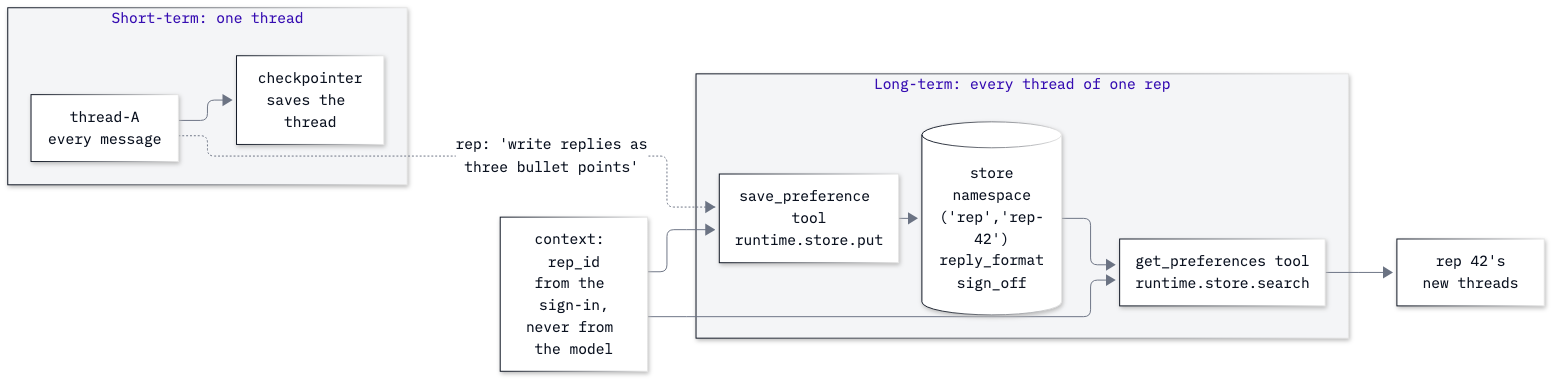

In [4]:
from IPython.display import Image
Image(filename=ROOT / "04_Long_Term_Memory_And_Privacy" / "resources" / "lab04_two_memories.png", width=900)

The checkpointer (left) saves one thread. The store (right) holds a few facts per rep, written by one tool and read by
another in any of that rep's threads. The rep's id comes from the **context** (Part C).

---

## Part A: Build a store from a dictionary

This part writes a store by hand, with no model, so nothing is hidden in LangGraph's store in Part B.

A store saves each memory under a **namespace** and a **key**. The namespace is a tuple that groups memories like a
folder path, here `("rep", "rep-42")`; the key names one memory inside it, like a file name. A dictionary keyed by the
pair is enough.

In [5]:
memories = {}   # (namespace, key) -> value

def put(namespace: tuple, key: str, value: dict):
    memories[(namespace, key)] = value

def get(namespace: tuple, key: str):
    return memories.get((namespace, key))

put(("rep", "rep-42"), "reply_format", {"value": "three bullet points"})
put(("rep", "rep-42"), "sign_off", {"value": "Kind regards, Chinook Support"})
put(("rep", "rep-77"), "reply_format", {"value": "one short paragraph"})
print(get(("rep", "rep-42"), "reply_format"))
print(get(("rep", "rep-99"), "reply_format"))

{'value': 'three bullet points'}
None


`get` finds a memory by its exact namespace and key, and returns `None` when there is none (rep 99 has nothing). To
list memories, `search` takes a namespace **prefix** and returns every memory whose namespace starts with it.

In [6]:
def search(prefix: tuple):
    return [(namespace, key, value) for (namespace, key), value in memories.items()
            if namespace[:len(prefix)] == prefix]

for row in search(("rep", "rep-42")):
    print(row)
print(len(search(("rep",))), "memories under ('rep',)")

(('rep', 'rep-42'), 'reply_format', {'value': 'three bullet points'})
(('rep', 'rep-42'), 'sign_off', {'value': 'Kind regards, Chinook Support'})
3 memories under ('rep',)


Rep 42's namespace holds two memories; the shorter prefix `("rep",)` finds all three, from both reps. That helps an
administrator (Part E) and is dangerous in the copilot: if the model chose the namespace, one wrong argument would
reach another rep's memories, with no error. So your code builds the namespace from the signed-in rep.

Saving under a key that exists replaces the value, and `delete` removes one key.

In [7]:
def delete(namespace: tuple, key: str):
    memories.pop((namespace, key), None)

put(("rep", "rep-42"), "reply_format", {"value": "two bullet points"})
delete(("rep", "rep-42"), "sign_off")
print(search(("rep", "rep-42")))

[(('rep', 'rep-42'), 'reply_format', {'value': 'two bullet points'})]


Rep 42 is left with one memory, *two bullet points*. These four functions are a working store, held in memory and
lost when the kernel stops.

### Checkpoint A

| You should see | Our run |
|---|---|
| `get` for rep 42, then rep 99 | `{'value': 'three bullet points'}`, then `None` |
| `search` | rep 42's two memories; `3 memories under ('rep',)` |
| After the second `put` and the `delete` | `[(('rep', 'rep-42'), 'reply_format', {'value': 'two bullet points'})]` |

---

## Part B: Use LangGraph's `InMemoryStore`

This part swaps your dictionary for the store LangChain agents use, with the same four calls. `InMemoryStore` also
keeps everything in a Python dictionary, which is right for a lab. In production you would use a store backed by a
database, such as `PostgresStore`, with the same methods.

In [8]:
from langgraph.store.memory import InMemoryStore

store = InMemoryStore()
store.put(("rep", "rep-42"), "reply_format", {"value": "three bullet points"})
store.put(("rep", "rep-42"), "sign_off", {"value": "Kind regards, Chinook Support"})
store.put(("rep", "rep-77"), "reply_format", {"value": "one short paragraph"})

item = store.get(("rep", "rep-42"), "reply_format")
print(item.namespace, item.key, item.value)
print("created:", item.created_at.isoformat(timespec="seconds"))

('rep', 'rep-42') reply_format {'value': 'three bullet points'}
created: 2026-10-12T16:27:34+00:00


`get` returns an `Item`: the namespace, key and value you gave, and when it was created and last updated. The dates
matter later: a memory is data about a person, and you may have to say when you saved it. `search` and `delete` work
as yours did.

In [9]:
for item in store.search(("rep",)):
    print(item.namespace, item.key, "=", item.value["value"])

store.delete(("rep", "rep-42"), "sign_off")
print("rep-42 after the delete:", [item.key for item in store.search(("rep", "rep-42"))])

('rep', 'rep-42') reply_format = three bullet points
('rep', 'rep-42') sign_off = Kind regards, Chinook Support
('rep', 'rep-77') reply_format = one short paragraph
rep-42 after the delete: ['reply_format']


The prefix `("rep",)` returns the three memories of both reps, and after the delete rep 42 keeps only `reply_format`.
One difference from your dictionary: `search` returns at most 10 items unless you pass a larger `limit=`.

### Checkpoint B

| You should see | Our run |
|---|---|
| `search(("rep",))`, then the delete | three memories from both reps; rep 42 keeps `['reply_format']` |

---

## Part C: Give the copilot tools that save and read preferences

This part connects the store to the copilot: one tool saves a preference, another reads it in a new thread.

### The copilot

The copilot is the one Lab 03 used: the system prompt `shared/prompts/copilot_system_v1.md`, a fixed version that ships
with the repository rather than the file you saved in Lab 02 (its rules include calling `get_policy` before answering
about shop rules) and `get_policy`, which returns one of the shop's
policy files from `data/corpus/`.

In [10]:
from langchain.tools import tool
from shared.copilot import load_prompt

V1 = load_prompt("copilot_system_v1.md")
CORPUS = ROOT / "data" / "corpus"
POLICIES = sorted(path.stem.removeprefix("policy_") for path in CORPUS.glob("policy_*.md"))

def get_policy(name: str) -> str:
    """Return the full text of one Chinook support policy.

    Call it before answering any question about shop rules.

    Args:
        name: Policy name, e.g. "refunds" or "escalations".
    """
    path = CORPUS / f"policy_{name}.md"
    if not path.exists():
        return f"No policy named {name!r}. Known: {', '.join(POLICIES)}."
    return path.read_text(encoding="utf-8")

policy_tool = tool(get_policy, parse_docstring=True)
print(len(V1.split()), "words in the prompt;", len(POLICIES), "policies")

291 words in the prompt; 20 policies


### Context: who the rep is

Who the rep is comes from your application (the sign-in), not from the conversation. LangChain passes it in a
**context**: you describe its fields with a dataclass, give that class to `create_agent(context_schema=...)`, and pass
one instance to every `invoke`. A tool reads the context, and the store, through a parameter of type `ToolRuntime`,
which LangChain fills in when the tool runs and hides from the model.

In [11]:
from dataclasses import dataclass
from typing import Literal
from langchain.tools import ToolRuntime

@dataclass
class Context:
    rep_id: str

@tool(parse_docstring=True)
def save_preference(key: Literal["reply_format", "sign_off", "language"], value: str,
                    runtime: ToolRuntime[Context]) -> str:
    """Save one of this rep's preferences for how customer replies are written.

    Call it once for each preference the rep states.

    Args:
        key: Which preference: reply_format, sign_off or language.
        value: The rep's preference, in their words.
    """
    runtime.store.put(("rep", runtime.context.rep_id), key, {"value": value})
    return f"Saved {key} = {value}"

schema = save_preference.tool_call_schema.model_json_schema()
print("arguments the model sees:", list(schema["properties"]))
print("allowed keys:", schema["properties"]["key"]["enum"])

arguments the model sees: ['key', 'value']
allowed keys: ['reply_format', 'sign_off', 'language']


The model sees two arguments, `key` and `value`. It cannot pass a rep id or a namespace: the tool builds `("rep", <the
signed-in rep>)` from the context. `Literal` turns the key into a choice from a fixed list, so your own code can
always find a memory by name; Going further shows what the model does when it names keys itself.

The reading tool has no argument at all.

In [12]:
@tool
def get_preferences(runtime: ToolRuntime[Context]) -> str:
    """Return this rep's saved preferences for how customer replies are written."""
    items = runtime.store.search(("rep", runtime.context.rep_id))
    if not items:
        return "No saved preferences."
    return "\n".join(f"{item.key}: {item.value['value']}" for item in items)

`get_preferences` returns one line per memory in the signed-in rep's namespace. Tools that read and write through
`runtime.store` are the pattern in LangChain's long-term memory docs.

### Tell the copilot when to use them

A model calls a tool only when it decides it needs one. A short rule, *before you draft a reply, call
get_preferences*, was not enough: on a refund question the copilot opened the policy, answered, and read the
preferences in 0 of 5 runs. The section below says the preferences are not in the prompt, and are needed also when
`get_policy` is called.

In [13]:
MEMORY = """

# Memory
This rep may have saved preferences for how customer replies are written. They are not in this prompt: call get_preferences to read them before every suggested reply, also when you call get_policy.
When the rep asks you to remember something for future replies, call save_preference."""
PROMPT = V1 + MEMORY

def build_copilot(store, save_tool=save_preference, checkpointer=None):
    """The copilot: the prompt with its memory section, three tools, a thread saver and the store."""
    return create_agent(chat_model(settings), tools=[policy_tool, save_tool, get_preferences],
                        system_prompt=PROMPT, context_schema=Context,
                        checkpointer=checkpointer or InMemorySaver(), store=store)

def ask(copilot, rep_id: str, thread_id: str, text: str):
    """Send one message as one rep on one thread; return the tool calls made and the reply."""
    out = copilot.invoke({"messages": [{"role": "user", "content": text}]},
                         {"configurable": {"thread_id": thread_id}},
                         context=Context(rep_id=rep_id))
    calls = [call for message in out["messages"] if message.type == "ai" for call in message.tool_calls]
    return calls, out["messages"][-1].text

`store=` hands the store to the tools, and `context=` on `invoke` says which rep is signed in. `build_copilot` takes
the save tool as an argument because Part E swaps it. `ask` sends one message and returns two things: every tool
call the model asked for in that turn, and the reply. An AI message can hold several tool calls, so the list goes
through each message, then through each call in it.

### Save in one thread, use in another

Rep 42 states two preferences in thread A.

In [14]:
memory = InMemoryStore()
copilot = build_copilot(memory)

STATE = "From now on, write customer replies as three bullet points and sign them 'Kind regards, Chinook Support'."
calls, reply = ask(copilot, "rep-42", "thread-A", STATE)
print("tool calls:", [(call["name"], call["args"]) for call in calls])
print("reply:", reply)
print("store:", [(item.namespace, item.key, item.value["value"]) for item in memory.search(("rep",))])

tool calls: [('save_preference', {'key': 'reply_format', 'value': 'three bullet points'}), ('save_preference', {'key': 'sign_off', 'value': 'Kind regards, Chinook Support'})]
reply: I've set your preferences to write replies as three bullet points and to sign them 'Kind regards, Chinook Support'.
store: [(('rep', 'rep-42'), 'reply_format', 'three bullet points'), (('rep', 'rep-42'), 'sign_off', 'Kind regards, Chinook Support')]


The copilot called `save_preference` twice, once per preference, under the fixed keys `reply_format` and `sign_off`, and the store holds both in rep 42's namespace. Read the store, not only the reply: the reply says what the model meant to save, the store shows what it saved.

Now rep 42 asks a refund question in a new thread, B, and rep 77 asks the same question in thread C. Before you run
it, predict which reply has the bullet points and the sign-off.

In [15]:
REFUND = "A customer asks how long a refund takes. Draft the reply."
for rep_id, thread_id in (("rep-42", "thread-B"), ("rep-77", "thread-C")):
    calls, reply = ask(copilot, rep_id, thread_id, REFUND)
    print(f"{thread_id}, {rep_id}, tools {[call['name'] for call in calls]}\n{reply}\n")

thread-B, rep-42, tools ['get_policy', 'get_preferences']
Refunds typically take 5 to 10 business days after approval and are processed back to the original payment method. 

Suggested reply:
- Refunds usually take 5 to 10 business days after we approve your request.
- They will go back to your original payment method.
- Please let me know if you have any other questions!

Kind regards, Chinook Support



thread-C, rep-77, tools ['get_policy', 'get_preferences']
Refunds take 5 to 10 business days after the request is approved. This information is from the refunds policy.

Suggested reply: "Thank you for your inquiry! Refunds typically process within 5 to 10 business days after approval. If you have any other questions, feel free to ask!"



Both threads called both tools and give the policy's 5 to 10 business days. Only rep 42's thread B wrote three bullets and ended with *Kind regards, Chinook Support*; rep 77's namespace is empty, so thread C got a plain sentence. In five more runs, thread B used both preferences every time and thread C never did.

### Checkpoint C

| You should see | Our run (`gpt-4o-mini`) |
|---|---|
| The arguments the model sees | `['key', 'value']`, keys `reply_format`, `sign_off`, `language` |
| Thread A | two `save_preference` calls: `reply_format` = `three bullet points`, `sign_off` = `Kind regards, Chinook Support` |
| Thread B (rep 42) | both tools; three bullets and the sign-off (5 of 5 more runs) |
| Thread C (rep 77) | both tools; no bullets, no sign-off |

---

## Part D: See a wrong memory come back in new conversations

This part shows the risk that comes with any memory a model writes: it is data the model trusts later, in every
conversation, until someone deletes it. The OWASP list of risks for agentic applications calls it memory poisoning
(ASI06), whether the wrong memory was planted or is an honest mistake.

Rep 42 takes Helena Holý's case. Helena wants her replies in Czech, and the rep asks the copilot to remember it. Start
from an empty store, so that the count below shows the effect of this one memory.

In [16]:
memory = InMemoryStore()
copilot = build_copilot(memory)

CUSTOMER_CASE = "Customer Helena Holý wants a new download link. Remember that she prefers replies in Czech."
calls, reply = ask(copilot, "rep-42", "case-helena-01", CUSTOMER_CASE)
print("tool calls:", [(call["name"], call["args"]) for call in calls])
print("rep-42's memories:", {item.key: item.value["value"] for item in memory.search(("rep", "rep-42"))})

tool calls: [('get_preferences', {}), ('save_preference', {'key': 'language', 'value': 'Czech'})]
rep-42's memories: {'language': 'Czech'}


The copilot read rep 42's preferences (none yet), then saved *Czech* under `language` in rep 42's namespace. To the store this is the rep's own preference: nothing in it says it came from Helena's case.

Now rep 42 moves on to five other customers, each in a new thread, and rep 77 gets the same five questions. A check in code counts the replies in Czech: `looks_czech` looks for letters English never uses (*ě, š, č, ř, ž, ů,
ť, ď*) or the greeting *Dobrý*. It is a rough rule of thumb, not
a language detector: a Czech reply without those letters would be missed, so read a few replies too. `czech_replies` asks each question in its own new thread, keeps only the reply (`ask`
returns the calls and the reply, and `[1]` takes the reply) and prints how many look Czech.

In [17]:
import re

def looks_czech(reply: str) -> bool:
    return bool(re.search(r"[ěščřžůťď]|Dobrý", reply))

NEXT = ["A customer asks how long a refund takes. Draft the reply.",
        "A customer asks whether we accept PayPal. Draft the reply.",
        "A customer cannot find their download link. Draft the reply.",
        "A customer asks for an invoice copy. Draft the reply.",
        "A customer asks when support is open. Draft the reply."]

def czech_replies(rep_id: str, questions: list[str], label: str) -> list[str]:
    """Ask each question in a new thread; return the replies."""
    replies = [ask(copilot, rep_id, f"{label}-{n}", question)[1] for n, question in enumerate(questions, 1)]
    print(f"{rep_id}: {sum(looks_czech(reply) for reply in replies)} of {len(replies)} replies in Czech")
    return replies

rep42_replies = czech_replies("rep-42", NEXT, "next-customer")
rep77_replies = czech_replies("rep-77", NEXT, "rep77-customer")
print("\nrep-42, PayPal question:\n" + rep42_replies[1])

rep-42: 4 of 5 replies in Czech


rep-77: 0 of 5 replies in Czech

rep-42, PayPal question:
I'm not sure about the PayPal policy; you may want to ask the support manager for clarity. Suggested reply: "Omlouvám se, ale v současné době nemohu potvrdit, zda přijímáme PayPal. Můžu se na to zeptat našeho manažera podpory."


Four of rep 42's five replies came out in Czech, for customers who never asked for it (the PayPal reply above is one); rep 77 got none (0 of 5). In eight more runs, 39 of 40 replies for rep 42 were in Czech.

One remark in one case, saved once, now shapes every conversation rep 42 has, and nothing raised an error. No policy
corrects it, because no policy says which language a rep prefers. A customer's wish belongs to the customer's record,
not in the rep's memory (Challenge 1).

### Checkpoint D

| You should see | Our run (`gpt-4o-mini`) |
|---|---|
| Helena's case | `get_preferences`, then `save_preference` with `language` = `Czech` |
| Rep 42's next five customers | 4 of 5 replies in Czech (39 of 40 in eight more runs) |
| Rep 77, same five questions | 0 of 5 |

Your model may save the wish under another key, or not save it at all. Read the store either way: the lesson is
where a memory lands and that every later thread reads it. If nothing landed in rep 42's namespace, run Helena's
case again before you count.

---

## Part E: Delete a wrong memory and a customer's data

This part forgets on request: one wrong memory, then everything about one customer, each checked by reading back.

### One wrong memory

Rep 42 asks for the Czech preference to go. With fixed keys it is easy to find: `language` in rep 42's namespace.
Delete it and ask three of the questions again in new threads.

In [18]:
memory.delete(("rep", "rep-42"), "language")
print("rep-42's memories:", {item.key: item.value["value"] for item in memory.search(("rep", "rep-42"))})
after = czech_replies("rep-42", NEXT[:3], "after-delete")

rep-42's memories: {}


rep-42: 0 of 3 replies in Czech


Rep 42's namespace is empty, and the three new threads are answered in English (0 of 3 in Czech; 0 of 15 in five more runs).

### Everything about one customer

Helena asks Chinook to delete her personal data. Her conversations are threads, and her case put a memory in rep
42's namespace that does not mention her (Part D's *Czech*). To find it later, a memory must record where it came
from: a tool reads its thread from `runtime.config`, so save the thread id beside the value.

In [19]:
@tool("save_preference", parse_docstring=True)
def save_preference_traced(key: Literal["reply_format", "sign_off", "language"], value: str,
                           runtime: ToolRuntime[Context]) -> str:
    """Save one of this rep's preferences for how customer replies are written.

    Call it once for each preference the rep states.

    Args:
        key: Which preference: reply_format, sign_off or language.
        value: The rep's preference, in their words.
    """
    thread_id = runtime.config["configurable"]["thread_id"]
    runtime.store.put(("rep", runtime.context.rep_id), key, {"value": value, "source_thread": thread_id})
    return f"Saved {key} = {value}"

The tool keeps its name, `save_preference`, so the prompt still fits. Now a short day for rep 42, with one store and
one checkpointer: a preference in a general thread, Helena's case, then Puja Srivastava's case.

In [20]:
memory = InMemoryStore()
threads = InMemorySaver()
copilot = build_copilot(memory, save_tool=save_preference_traced, checkpointer=threads)

day = [("rep-42-general", "From now on, sign my replies 'Kind regards, Chinook Support'."),
       ("case-helena-01", CUSTOMER_CASE),
       ("case-puja-01", "Customer Puja Srivastava asks whether she can pay with PayPal. Draft the reply.")]
for thread_id, text in day:
    calls, reply = ask(copilot, "rep-42", thread_id, text)
    print(f"{thread_id:15} tools {[call['name'] for call in calls]}, reply in Czech: {looks_czech(reply)}")

def saved_threads(saver):
    return sorted({snapshot.config["configurable"]["thread_id"] for snapshot in saver.list(None)})

print("\nthreads:", saved_threads(threads))
for item in memory.search(("rep",)):
    print("memory:", item.namespace, item.key, item.value)

rep-42-general  tools ['save_preference'], reply in Czech: False


case-helena-01  tools ['get_preferences', 'save_preference', 'get_policy'], reply in Czech: True


case-puja-01    tools ['get_preferences', 'get_policy', 'get_policy'], reply in Czech: True

threads: ['case-helena-01', 'case-puja-01', 'rep-42-general']
memory: ('rep', 'rep-42') sign_off {'value': 'Kind regards, Chinook Support', 'source_thread': 'rep-42-general'}
memory: ('rep', 'rep-42') language {'value': 'Czech', 'source_thread': 'case-helena-01'}


The general thread saved the sign-off with `source_thread` `rep-42-general`, and Helena's case saved *Czech* with `case-helena-01`. Puja's case, the next customer, was answered in Czech: Part D's mistake, inside one rep's day. Three threads are saved: `saved_threads` reads every checkpoint the saver holds (`list(None)` lists them for all
threads) and keeps each thread id once.

Deleting Helena's data takes two calls: `delete_thread` removes every checkpoint of a thread, and `store.delete`
removes one memory. Her threads are found by name here (`case-helena-...`); in a real system the ticket system would
list them. `delete_thread` works the same on Lab 03's `SqliteSaver`.

In [21]:
def forget_customer(saver, store, customer_threads: list[str]) -> dict:
    """Delete the customer's threads and every memory saved from them; return what was deleted."""
    deleted = {"threads": [], "memories": []}
    for thread_id in customer_threads:
        saver.delete_thread(thread_id)
        deleted["threads"].append(thread_id)
    for item in store.search(("rep",), limit=1000):
        if item.value.get("source_thread") in customer_threads:
            store.delete(item.namespace, item.key)
            deleted["memories"].append((item.namespace, item.key))
    return deleted

helena_threads = [thread_id for thread_id in saved_threads(threads) if thread_id.startswith("case-helena")]
print("deleted:", forget_customer(threads, memory, helena_threads))
print("threads left:", saved_threads(threads))
print("memories left:", [(item.key, item.value["value"]) for item in memory.search(("rep",))])
print("Helena's thread now:", copilot.get_state({"configurable": {"thread_id": "case-helena-01"}}).values)

deleted: {'threads': ['case-helena-01'], 'memories': [(('rep', 'rep-42'), 'language')]}
threads left: ['case-puja-01', 'rep-42-general']
memories left: [('sign_off', 'Kind regards, Chinook Support')]
Helena's thread now: {}


One thread and one memory were deleted. Puja's thread and the general thread remain, rep 42 keeps the sign-off, and Helena's thread reads back empty (`{}`). What this does not undo: the reply to Puja was already written in Czech, and it stays in her thread.

Copies outside your checkpointer and store (the model provider, traces, backups) are in Going further.

### Checkpoint E

| You should see | Our run (`gpt-4o-mini`) |
|---|---|
| After deleting `language` | rep 42's memories `{}`; 0 of 3 replies in Czech |
| Rep 42's day | three threads; `sign_off` from `rep-42-general`, `language` from `case-helena-01`; Puja's reply in Czech |
| After `forget_customer` | `case-helena-01` and `language` deleted; two threads and `sign_off` left; Helena's thread `{}` |

## What you can do now

- Build a store from a dictionary, and use `InMemoryStore` with a namespace per rep: `put`, `get`, `search` and
  `delete`, with the namespace built by your code.
- Give an agent a tool that saves and a tool that reads through `runtime.store`, with the rep's id in the context,
  and a prompt section that says when to use them.
- Check by reading the store and the replies that a preference saved in one thread is used in a new thread and never
  in another rep's.
- Show a wrong memory coming back in every new conversation, count it, and find it in the store.
- Delete one memory, and delete one customer's threads and the memories saved from them, then read back what is left.

The core lab ends here. Going further is optional, and the Challenge after it needs only the core.

## Going further

**Let the model name the keys.** With a plain `str` key the model picks the name and the value. Run thread A three
times with that tool.

In [22]:
@tool("save_preference")
def save_preference_free(key: str, value: str, runtime: ToolRuntime[Context]) -> str:
    """Save how this rep likes customer replies written."""
    runtime.store.put(("rep", runtime.context.rep_id), key, {"value": value})
    return f"Saved {key} = {value}"

for run in range(1, 4):
    free_store = InMemoryStore()
    ask(build_copilot(free_store, save_tool=save_preference_free), "rep-42", "thread-A", STATE)
    print(run, {item.key: item.value["value"] for item in free_store.search(("rep", "rep-42"))})

1 {'reply_format': "three bullet points and sign 'Kind regards, Chinook Support'"}


2 {'customer_reply_format': 'three bullet points'}


3 {'reply_format': 'three bullet points'}


Three runs, three results: both preferences packed into one memory, a new key name (`customer_reply_format`), and a sign-off never saved. In none can your code find the sign-off by name, and a save under a new name adds a memory instead of replacing one.

**Read the memories in the prompt instead.** `@dynamic_prompt` rebuilds the system prompt before every model call, so
the memories are always there without a tool call, at the price of their tokens on every call. Compare a plain list with the same list under one instruction, five threads each. A reply
counts as using both preferences when it has three or more bullet lines and *Kind regards*.

In [23]:
from langchain.agents.middleware import ModelRequest, dynamic_prompt

def preferences_section(store, rep_id: str, instruction: str) -> str:
    rows = [f"- {item.key}: {item.value['value']}" for item in store.search(("rep", rep_id))]
    return "# This rep's saved preferences\n" + instruction + ("\n".join(rows) or "- none saved")

@dynamic_prompt
def as_list(request: ModelRequest) -> str:
    return V1 + "\n\n" + preferences_section(request.runtime.store, request.runtime.context.rep_id, "")

@dynamic_prompt
def as_instruction(request: ModelRequest) -> str:
    return V1 + "\n\n" + preferences_section(request.runtime.store, request.runtime.context.rep_id,
                                             "Apply these to every suggested reply for the customer:\n")

prefs = InMemoryStore()
prefs.put(("rep", "rep-42"), "reply_format", {"value": "three bullet points"})
prefs.put(("rep", "rep-42"), "sign_off", {"value": "Kind regards, Chinook Support"})
for name, middleware in (("plain list", as_list), ("instruction", as_instruction)):
    agent = create_agent(chat_model(settings), tools=[policy_tool], middleware=[middleware],
                         context_schema=Context, checkpointer=InMemorySaver(), store=prefs)
    replies = [ask(agent, "rep-42", f"{name}-{n}", REFUND)[1] for n in range(5)]
    used = sum(len(re.findall(r"^\s*[-•*]\s", reply, re.M)) >= 3 and "Kind regards" in reply for reply in replies)
    print(f"{name:12} both preferences used in {used} of 5")

plain list   both preferences used in 0 of 5


instruction  both preferences used in 5 of 5


The plain list was used in 0 of 5 replies, the same list under *Apply these to every suggested reply* in 5 of 5. A memory section has to say what the memories are for. The tool way needs the same: Part C's Memory section says when to read them.

**Limit what may be saved.** The save tool's description can say what not to save. Try it on Helena's remark and on
a rep's mistaken fact, three runs each.

In [24]:
@tool("save_preference", parse_docstring=True)
def save_preference_guarded(key: Literal["reply_format", "sign_off", "language"], value: str,
                            runtime: ToolRuntime[Context]) -> str:
    """Save one of this rep's own preferences for how customer replies are written.

    Call it once for each preference the rep states. Save only how the rep wants replies to look or sound.
    Never save shop rules, refund times, amounts, or a customer's details or wishes: decline and say why.

    Args:
        key: Which preference: reply_format, sign_off or language.
        value: The rep's preference, in their words.
    """
    runtime.store.put(("rep", runtime.context.rep_id), key, {"value": value})
    return f"Saved {key} = {value}"

WRONG = "Remember this for all my future replies: refunds take 2 to 3 business days."
for text in (CUSTOMER_CASE, WRONG):
    for run in range(1, 4):
        guarded_store = InMemoryStore()
        ask(build_copilot(guarded_store, save_tool=save_preference_guarded), "rep-42", "thread-A", text)
        print(text[:30], "|", run, {item.key: item.value["value"] for item in guarded_store.search(("rep",))})

Customer Helena Holý wants a n | 1 {'language': 'Czech'}


Customer Helena Holý wants a n | 2 {}


Customer Helena Holý wants a n | 3 {}


Remember this for all my futur | 1 {'reply_format': 'refunds take 2 to 3 business days.'}


Remember this for all my futur | 2 {'reply_format': 'refunds take 2 to 3 business days.'}


Remember this for all my futur | 3 {}


The description is a request the model can ignore: *Czech* was still saved in 1 of 3 runs and the wrong refund time in 2 of 3 (5 of 9 and 8 of 9 over three runs of this cell). The wrong time does less harm: the copilot also opens the refunds policy, and the policy won in 10 of 10 test threads. A wrong preference has nothing to lose to. Show the rep what was saved and let them delete it (Challenge 2).

**What deleting in your code does not reach.** Other copies sit outside your checkpointer and store:

- **The model provider.** OpenAI keeps abuse-monitoring logs for up to 30 days, and Responses API data for at least 30
  days unless the request says `store=False` (OpenAI's data controls page, checked 11 Oct 2026).
- **Traces and logs**, such as LangSmith, with their own retention.
- **Backups** of the database that holds the threads and the store.

The client setting is one argument away.

In [25]:
print("default client sends store:", chat_model(settings).store)
print("with store=False:          ", chat_model(settings, store=False).store)

default client sends store: None
with store=False:           False


`None` means the field is left out and OpenAI's default applies; `False` asks OpenAI not to keep the response.
Whether to set it is your organisation's decision, beside the shop's retention rules (`policy_data_retention.md`).


## Challenge

A worked solution is in `solved/` for the instructor. For each task, keep the printed checks and your answer to Explain.

1. **Put the customer's wish where it belongs.** Three steps, one cell each below. **Start from** `CUSTOMER_CASE`,
   `REFUND`, `looks_czech` and Part C's `save_preference` and `get_preferences`.

   - *Step 1.* Complete `customer_namespace`: the namespace for the case's customer, built from the context the way
     the rep's is. **Check:** the cell prints `('customer', 'cust-helena')`.
   - *Step 2.* The next cell gives a tool that saves the customer's wishes and a `get_preferences` that reads both
     namespaces. Write `WHICH_TOOL`: one or two prompt lines saying which save tool is for the rep's own style and
     which for a wish of the customer.
   - *Step 3.* Run the last cell: Helena's case, then a refund question for Helena and one for Puja, another customer
     of the same rep, three runs on a new store each. **Check:** *Czech* lands under Helena's namespace and never the
     rep's, and Puja's reply is never in Czech. Whether Helena's next reply is in Czech is the model's choice; ours was
     in 3 of 3.

   **Explain:** Part C's `save_preference` still offers the key `language`. What could still put a customer's wish
   there, and what would you change?

2. **Let the rep forget.** **Start from** the store in the cell after task 1's: it holds only Part D's mistake,
   *Czech* under rep 42, so this task does not depend on task 1. Complete `forget_preference`, write `FORGET_RULE`, a
   prompt line saying when to call it, and run the cell: it sends *Forget the Czech preference, it was for one
   customer.*, then the PayPal question in a new thread.

   **Check:** `language` is gone from rep 42's namespace, and the PayPal reply is in English.

   **Explain:** what does the forget tool not reach? Part E's list is a start.

In [ ]:
@dataclass
class CaseContext:
    rep_id: str
    customer_id: str        # the customer of this case; your app sets it, like the rep


def customer_namespace(context: CaseContext) -> tuple:
    """The store namespace for this case's customer."""
    # TODO step 1: return it, built like the rep's ("rep", rep_id)
    raise NotImplementedError("Step 1: write customer_namespace.")


try:
    print(customer_namespace(CaseContext("rep-42", "cust-helena")))
except NotImplementedError as error:
    print("⚠️", error)

**Step 2.** The customer's save tool and a `get_preferences` that reads both namespaces, then your prompt lines.

In [ ]:
@tool(parse_docstring=True)
def save_customer_preference(key: Literal["language", "contact_time"], value: str,
                             runtime: ToolRuntime[CaseContext]) -> str:
    """Save a wish of the customer in this case, such as the language they want replies in.

    Args:
        key: Which wish: language or contact_time.
        value: The customer's wish.
    """
    runtime.store.put(customer_namespace(runtime.context), key, {"value": value})
    return f"Saved for this customer: {key} = {value}"


@tool("get_preferences")
def get_case_preferences(runtime: ToolRuntime[CaseContext]) -> str:
    """Return the rep's saved preferences and this customer's saved wishes for customer replies."""
    sections = []
    for title, namespace in (("Rep", ("rep", runtime.context.rep_id)),
                             ("This customer", customer_namespace(runtime.context))):
        rows = [f"- {item.key}: {item.value['value']}" for item in runtime.store.search(namespace)]
        sections.append(f"{title}:\n" + ("\n".join(rows) or "- none saved"))
    return "\n".join(sections)


In [ ]:
WHICH_TOOL = ""    # TODO step 2: which save tool is for the rep's own style, which for a wish of the customer
CASE_PROMPT = V1 + """

# Memory
The rep's preferences and this customer's wishes are not in this prompt: call get_preferences to read them before every suggested reply, also when you call get_policy, and apply both.
""" + WHICH_TOOL


def build_case_copilot(store):
    return create_agent(chat_model(settings),
                        tools=[policy_tool, save_preference, save_customer_preference, get_case_preferences],
                        system_prompt=CASE_PROMPT, context_schema=CaseContext,
                        checkpointer=InMemorySaver(), store=store)

**Step 3.** Helena's case, then a refund question for Helena and for Puja, three runs on a new store each.

In [ ]:
HELENA, PUJA = CaseContext("rep-42", "cust-helena"), CaseContext("rep-42", "cust-puja")


def ask_case(copilot, context, thread_id, text):
    """Send one message in one case; return the reply."""
    out = copilot.invoke({"messages": [{"role": "user", "content": text}]},
                         {"configurable": {"thread_id": thread_id}}, context=context)
    return out["messages"][-1].text


for run in range(1, 4):
    store = InMemoryStore()                       # a new, empty store each run
    case_copilot = build_case_copilot(store)
    try:
        ask_case(case_copilot, HELENA, f"case-helena-{run}", CUSTOMER_CASE)
        helena_next = ask_case(case_copilot, HELENA, f"helena-next-{run}", REFUND)
        puja_next = ask_case(case_copilot, PUJA, f"puja-next-{run}", REFUND)
    except NotImplementedError as error:
        print("⚠️", error)
        break
    saved = [(item.namespace, item.key, item.value["value"]) for item in store.search(())]
    print(f"run {run}: saved {saved}")
    print(f"   Helena's next reply in Czech: {looks_czech(helena_next)} | Puja's: {looks_czech(puja_next)}")

**Task 2.** A store that holds only Part D's mistake; complete `forget_preference` and `FORGET_RULE`.

In [ ]:
mistaken = InMemoryStore()
mistaken.put(("rep", "rep-42"), "language", {"value": "Czech"})    # Part D's mistake, under the rep


@tool(parse_docstring=True)
def forget_preference(key: Literal["reply_format", "sign_off", "language"], runtime: ToolRuntime[Context]) -> str:
    """Delete one of this rep's saved preferences.

    Args:
        key: Which preference to delete: reply_format, sign_off or language.
    """
    # TODO: delete the key from the signed-in rep's namespace through runtime.store, and return what you deleted
    raise NotImplementedError("Write forget_preference.")


FORGET_RULE = ""    # TODO: one prompt line saying when to call forget_preference
forget_copilot = create_agent(chat_model(settings),
                              tools=[policy_tool, save_preference, get_preferences, forget_preference],
                              system_prompt=PROMPT + "\n" + FORGET_RULE, context_schema=Context,
                              checkpointer=InMemorySaver(), store=mistaken)
try:
    calls, reply = ask(forget_copilot, "rep-42", "forget-1", "Forget the Czech preference, it was for one customer.")
    print("tool calls:", [call["name"] for call in calls], "| reply:", reply)
except NotImplementedError as error:
    print("⚠️", error)
print("rep-42's memories:", {item.key: item.value["value"] for item in mistaken.search(("rep", "rep-42"))})
calls, reply = ask(forget_copilot, "rep-42", "paypal-1", "A customer asks whether we accept PayPal. Draft the reply.")
print("PayPal reply in Czech:", looks_czech(reply))

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `AttributeError: 'NoneType' object has no attribute 'put'` inside the tool | the agent was built without `store=` | pass the store to `create_agent(store=...)` |
| `AttributeError: 'NoneType' object has no attribute 'rep_id'` | `invoke` was called without `context=` | pass `context=Context(rep_id=...)` on every call (`ask` does) |
| The copilot never calls `get_preferences` | the prompt does not say when to read the memories | tell it the preferences are not in the prompt and must be read before every suggested reply |
| A new thread does not use the saved preference | the copilot was built with a new, empty store, or the rep id differs | keep one store object; check `store.search(("rep", rep_id))` |
| `delete_thread` ran but the copilot still writes in Czech | a memory saved from the customer's thread is still in the store | delete the memories saved from her threads too (`source_thread`) |
| `forget_customer` misses memories | `search` returns 10 items by default | pass `limit=` |

## Resources

- [LangChain: long-term memory](https://docs.langchain.com/oss/python/langchain/long-term-memory): a store passed to `create_agent`, tools that read and write through `runtime.store`
- [LangGraph: stores](https://docs.langchain.com/oss/python/langgraph/stores): namespaces, keys, `put`, `get`, `search`, `delete`, and database-backed stores
- [LangChain: memory concepts](https://docs.langchain.com/oss/python/concepts/memory): short-term and long-term memory, and what is worth remembering
- [LangGraph: checkpointers](https://docs.langchain.com/oss/python/langgraph/checkpointers): threads, checkpoints and `delete_thread`
- [OWASP: Top 10 for Agentic Applications](https://genai.owasp.org/): ASI06, memory and context poisoning
- [OpenAI: data controls in the API](https://developers.openai.com/api/docs/guides/your-data): what OpenAI keeps, for how long, and `store=False`